# Task 1 training and straight solution paths for four algorithms

Each panel plots the task 1 mean training curve from `plot_iqm.py --compute-only` and both straight parameter-space segments from `linear_grid.ipynb`: θ₁ → θ₂ → θ₃. The horizontal axis is cumulative training timesteps; the vertical axis is return divided by the environment maximum. θ₁, θ₂, and θ₃ are aligned with the task 1, 2, and 3 checkpoints. Both shaded bands are 95% bootstrap confidence intervals over seeds. The training curve and band come from the `mean_ci` compute-only CSV; the path mean and band are computed from the per-seed grids.

Grid returns are bilinear estimates along the exact parameter-space segments, because the 200 × 200 saved grids do not sample the endpoint coordinates exactly. The selected grids have endpoint returns consistent with the training CSVs; an endpoint check below catches large mismatches.


In [1]:
from pathlib import Path
import sys

STYLE_ROOT = Path.cwd()
if not (STYLE_ROOT / "scripts" / "plot_style.py").is_file():
    STYLE_ROOT = STYLE_ROOT.parent
if not (STYLE_ROOT / "scripts" / "plot_style.py").is_file():
    raise FileNotFoundError("Start the notebook in the repository root or scripts/.")
sys.path.insert(0, str(STYLE_ROOT))
sys.path.insert(0, str(STYLE_ROOT / "scripts"))
# Reload edits from disk when rerunning this cell in an existing kernel.
import importlib
from scripts import plot_style
importlib.reload(plot_style)
from scripts.plot_style import (
    apply_style, figure_size, export_figure, bottom_legend, FONT_SIZE, STROKES,
)
apply_style()

from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sys
from matplotlib.ticker import FuncFormatter

ROOT = Path.cwd()
if not (ROOT / "scripts" / "plot_iqm.py").is_file():
    ROOT = ROOT.parent
if not (ROOT / "scripts" / "plot_iqm.py").is_file():
    raise FileNotFoundError("Start the kernel in the repository root or scripts/.")
sys.path.insert(0, str(ROOT))
from scripts.common import bootstrap_mean

# Edit a panel's CSV and grid together when selecting a different run.
COMMON = {"plot_index": 0, "line_index": 0, "seeds": range(50),
          "num_tasks": 3, "path_points": 101,
          "path_segments": [("theta1", "theta2"), ("theta2", "theta3")]}
PLOTS = [
    {**COMMON, "title": "DQN", "training_csv": ROOT / "output/plots/joint_incremental/ji-dqn_data.csv",
     "grid_template": ROOT / "output/interpolations/joint_incremental/ji-dqn/data_{seed}.csv",
     "timesteps_per_task": 200_000, "max_return": 500.0},
    {**COMMON, "title": "SAC-D", "training_csv": ROOT / "output/plots/joint_incremental/ji-sacd_data.csv",
     "grid_template": ROOT / "output/interpolations/joint_incremental/ji-sacd-l_00001/data_{seed}.csv",
     "timesteps_per_task": 150_000, "max_return": 500.0},
    {**COMMON, "title": "DDPG", "training_csv": ROOT / "output/plots/joint_incremental/ji-ddpg_data.csv",
     "grid_template": ROOT / "output/interpolations/joint_incremental/ji-ddpg/data_{seed}.csv",
     "timesteps_per_task": 150_000, "max_return": 1000.0},
    {**COMMON, "title": "SAC", "training_csv": ROOT / "output/plots/joint_incremental/ji-sac_data.csv",
     "grid_template": ROOT / "output/interpolations/joint_incremental/ji-sac/data_{seed}.csv",
     "timesteps_per_task": 150_000, "max_return": 1000.0},
]
SOLUTIONS = {"theta1": (0.0, 1.0), "theta2": (1.0, 1.0), "theta3": (1.0, 0.0)}
SOLUTION_CHECKPOINT = {"theta1": 1, "theta2": 2, "theta3": 3}
TRAIN_COLOR = "#E69F00"
PATH_COLOR = "#D62728"
X_LABEL = r"Timesteps ($\times 10^5$)"
Y_LABEL = "Mean Normalized Return"
SAVE = True
OUT = ROOT / "output/plots/notebook"
OUTPUT_STEM = "task1_training_linear_paths_four_algorithms_mean_ci"



In [2]:
def load_training(cfg):
    path = Path(cfg["training_csv"])
    frame = pd.read_csv(path)
    required = {"plot_index", "line_index", "aggregation", "timestep", "center", "lower", "upper"}
    if not required.issubset(frame):
        raise ValueError(f"{path} is missing {sorted(required - set(frame))}")
    selected = frame.loc[(frame.plot_index == cfg["plot_index"]) &
                         (frame.line_index == cfg["line_index"])].copy()
    if selected.empty:
        raise ValueError("No matching training line; check plot_index and line_index.")
    if set(selected["aggregation"].dropna()) != {"mean_ci"}:
        raise ValueError(f"{path} must contain mean_ci data, not IQM or standard-error data.")
    selected = selected.sort_values("timestep")
    for column in ("timestep", "center", "lower", "upper"):
        selected[column] = pd.to_numeric(selected[column], errors="raise")
    selected = selected.loc[np.isfinite(selected[["timestep", "center", "lower", "upper"]]).all(axis=1)]
    if selected.empty or (selected.lower > selected.upper).any():
        raise ValueError("Training line has no finite data or invalid uncertainty bounds.")
    return selected


def read_grid(path):
    frame = pd.read_csv(path, header=None, names=["alpha", "beta", "reward"])
    if frame.empty or not np.isfinite(frame.to_numpy(dtype=float)).all():
        raise ValueError(f"Empty or non-finite interpolation grid: {path}")
    grid = frame.pivot(index="beta", columns="alpha", values="reward").sort_index().sort_index(axis=1)
    if grid.isna().any().any():
        raise ValueError(f"Incomplete interpolation grid: {path}")
    return grid.index.to_numpy(dtype=float), grid.columns.to_numpy(dtype=float), grid.to_numpy(dtype=float)


def grid_performance(beta_axis, alpha_axis, rewards, alpha, beta):
    """Bilinear reward estimate at exact (alpha, beta) parameter coordinates."""
    if not (alpha_axis[0] <= alpha <= alpha_axis[-1] and beta_axis[0] <= beta <= beta_axis[-1]):
        raise ValueError("Path lies outside the evaluation grid.")
    below = np.searchsorted(beta_axis, beta, side="right") - 1
    below = int(np.clip(below, 0, len(beta_axis) - 2))
    weight = (beta - beta_axis[below]) / (beta_axis[below + 1] - beta_axis[below])
    lower = np.interp(alpha, alpha_axis, rewards[below])
    upper = np.interp(alpha, alpha_axis, rewards[below + 1])
    return (1 - weight) * lower + weight * upper


def load_paths(cfg):
    if cfg["path_points"] < 2 or not list(cfg["seeds"]):
        raise ValueError("Use at least two path points and one seed.")
    progress = np.linspace(0, 1, cfg["path_points"])
    segments = cfg["path_segments"]
    if not segments:
        raise ValueError("Select at least one path segment.")
    coordinates = []
    for start_name, end_name in segments:
        start = np.asarray(SOLUTIONS[start_name], dtype=float)
        end = np.asarray(SOLUTIONS[end_name], dtype=float)
        coordinates.extend(start[None, :] + progress[:, None] * (end - start)[None, :])
    per_seed = []
    for seed in cfg["seeds"]:
        path = Path(str(cfg["grid_template"]).format(seed=seed))
        if not path.is_file():
            raise FileNotFoundError(f"Missing grid for seed {seed}: {path}")
        beta_axis, alpha_axis, rewards = read_grid(path)
        per_seed.append([grid_performance(beta_axis, alpha_axis, rewards, a, b)
                         for a, b in coordinates])
    values = np.asarray(per_seed, dtype=float).T  # (path points, seeds)
    if not np.isfinite(values).all():
        raise ValueError("Non-finite path rewards in interpolation grids.")
    center, lower, upper = bootstrap_mean(values, n_bootstrap=10_000, confidence=.95)
    return [(start_name, end_name, progress,
             center[i * len(progress):(i + 1) * len(progress)],
             lower[i * len(progress):(i + 1) * len(progress)],
             upper[i * len(progress):(i + 1) * len(progress)])
            for i, (start_name, end_name) in enumerate(segments)]

def validate_endpoints(cfg, training, paths):
    """Reject a grid whose checkpoint returns conflict strongly with training."""
    for start_name, end_name, _, rewards, _, _ in paths:
        for name, path_return in ((start_name, rewards[0]), (end_name, rewards[-1])):
            checkpoint_time = SOLUTION_CHECKPOINT[name] * cfg["timesteps_per_task"]
            closest = training.iloc[(training.timestep - checkpoint_time).abs().argmin()]
            if abs(closest.timestep - checkpoint_time) > cfg["timesteps_per_task"] * .01:
                raise ValueError(f"{cfg['title']}: no training measurement near {name}.")
            discrepancy = abs(path_return - closest.center) / cfg["max_return"]
            if discrepancy > .1:
                raise ValueError(
                    f"{cfg['title']} {name}: grid return {path_return:.1f} disagrees with "
                    f"training return {closest.center:.1f}; check grid_template."
                )

panel_data = []
for cfg in PLOTS:
    training = load_training(cfg)
    paths = load_paths(cfg)
    validate_endpoints(cfg, training, paths)
    panel_data.append((cfg, training, paths))
    print(f"{cfg['title']}: {len(training)} training points; {len(list(cfg['seeds']))} path seeds")


DQN: 2748 training points; 50 path seeds
SAC-D: 2598 training points; 50 path seeds
DDPG: 2598 training points; 50 path seeds
SAC: 2598 training points; 50 path seeds


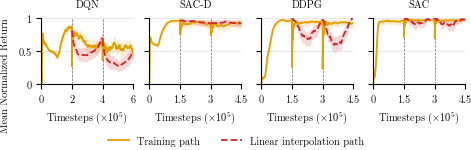

'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
webf NOT subset; don't know how to subset; dropped


Saved /home/seb/Code/uni/stability-gap-drl/output/plots/notebook/task1_training_linear_paths_four_algorithms_mean_ci.pdf
Saved /home/seb/Code/uni/stability-gap-drl/output/plots/notebook/task1_training_linear_paths_four_algorithms_mean_ci.png
Saved /home/seb/Code/uni/stability-gap-drl/output/plots/notebook/task1_training_linear_paths_four_algorithms_mean_ci.svg


In [3]:
def format_timestep(value, _position):
    return f"{value / 100_000:g}"

if len(panel_data) != 4:
    raise ValueError("Expected DQN, SAC-D, DDPG, and SAC panels.")
fig, axes = plt.subplots(1, 4, figsize=figure_size("training_paths"), sharey=True, layout="constrained")
for ax, (cfg, training, paths) in zip(axes, panel_data):
    max_return = float(cfg["max_return"])
    total_steps = cfg["timesteps_per_task"] * cfg["num_tasks"]
    if max_return <= 0 or total_steps <= 0:
        raise ValueError(f"{cfg['title']}: max_return and total steps must be positive.")
    times = training.timestep.to_numpy(dtype=float)
    ax.plot(times, training.center.to_numpy() / max_return,
            color=TRAIN_COLOR, label="Training path")
    ax.fill_between(times, training.lower.to_numpy() / max_return,
                    training.upper.to_numpy() / max_return,
                    color=TRAIN_COLOR, alpha=.18, linewidth=STROKES["band_edge"])
    for index, (start_name, end_name, progress, reward, lower, upper) in enumerate(paths):
        path_times = cfg["timesteps_per_task"] * (
            SOLUTION_CHECKPOINT[start_name] + progress *
            (SOLUTION_CHECKPOINT[end_name] - SOLUTION_CHECKPOINT[start_name]))
        ax.plot(path_times, reward / max_return, linestyle="--", color=PATH_COLOR,
                label="Linear interpolation path" if index == 0 else None)
        ax.fill_between(path_times, lower / max_return, upper / max_return,
                        color=PATH_COLOR, alpha=.18, linewidth=STROKES["band_edge"])
    for boundary in range(1, cfg["num_tasks"]):
        ax.axvline(boundary * cfg["timesteps_per_task"], color="0.4",
                   linewidth=STROKES["task_boundary"], linestyle="--", zorder=0)
    ax.set_title(cfg["title"], pad=8)
    ax.set_xlim(0, total_steps)
    ax.set_ylim(0, 1)
    ax.set_yticks([0, .5, 1], labels=["0", "0.5", "1"])
    ax.set_xticks(np.arange(cfg["num_tasks"] + 1) * cfg["timesteps_per_task"])
    ax.xaxis.set_major_formatter(FuncFormatter(format_timestep))
    ax.grid(axis="y", color="0.8", alpha=.65)
    ax.spines[["top", "right"]].set_visible(False)
    ax.set_xlabel(X_LABEL)
fig.supylabel(Y_LABEL)
handles, labels = axes[0].get_legend_handles_labels()
bottom_legend(fig, handles, labels, ncol=2)
plt.show()

if SAVE:
    OUT.mkdir(parents=True, exist_ok=True)
    for suffix in ("pdf", "png", "svg"):
        output = OUT / f"{OUTPUT_STEM}.{suffix}"
        export_figure(fig, output, dpi=300)
        print(f"Saved {output}")
